# 01 · Dataset exploration

**Objective.** Understand the real METR-LA data *before* any modelling: structure, time grid, how missing readings are
encoded, how much is missing, descriptive statistics, and daily / weekly traffic patterns.

**Methodology.**
1. Inspect the HDF5 layout and load it (`h5py`, strict schema checks).
2. Establish the timestamp frequency, sensor count, duplicates.
3. Work out how missing readings are encoded and quantify missingness and outages.
4. Descriptive statistics, representative sensors, network-wide average speed.
5. Time-of-day / day-of-week structure, which also justifies the peak windows fixed in `src/config.py`
   (decided here, **before** any model exists).
6. State the limitations of the data.

Nothing in this notebook alters the data; it only reads.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, visualization as viz

viz.apply_style()
dl.require_raw_files()

## 1 · HDF5 structure

`metr-la.h5` was written by pandas (`HDFStore`, key `df`). We read the raw HDF5 datasets with `h5py` instead of
`pandas.read_hdf`, because pandas' fixed-format reader can unpickle object arrays embedded in a file, and this file
comes from a third-party mirror. The loader refuses any object-dtype dataset.

In [3]:
layout = dl.inspect_h5()
print("root keys:", layout["root_keys"])
for name, info in layout["datasets"].items():
    print(f"  dataset {name:18s} shape={str(info['shape']):14s} dtype={info['dtype']}")
print("group attributes of 'df':", {k: v for k, v in layout["group_attrs"]["df"].items() if k in ("pandas_type", "pandas_version", "nblocks", "ndim")})

root keys: ['df']
  dataset df/axis0           shape=(207,)         dtype=|S6
  dataset df/axis1           shape=(34272,)       dtype=int64
  dataset df/block0_items    shape=(207,)         dtype=|S6
  dataset df/block0_values   shape=(34272, 207)   dtype=float64
group attributes of 'df': {'nblocks': '1', 'ndim': '2', 'pandas_type': 'frame', 'pandas_version': '0.15.2'}


**Reading the layout.** `axis0` holds the 207 sensor ids as fixed-width byte strings, `axis1` the timestamps as int64
nanoseconds, and `block0_values` the `[time x sensor]` float64 speed matrix: a plain pandas `DataFrame` with a
`DatetimeIndex`. Nothing requires unpickling.

## 2 · Dimensions, index, identifiers and time grid

In [4]:
raw = dl.load_metr_la_h5()
values, timestamps, sensor_ids = raw.values, raw.timestamps, raw.sensor_ids
T, N = values.shape
frame = pd.DataFrame(values, index=timestamps, columns=sensor_ids)   # inspection view only

print(f"observations (time steps): {T:,}   sensors: {N}   cells: {T * N:,}")
print(f"first timestamp: {timestamps[0]}   last timestamp: {timestamps[-1]}")
print(f"dtype: {frame.dtypes.unique()}   index dtype: {frame.index.dtype}   index name: {frame.index.name}")
print(f"sensor ids are {type(sensor_ids[0]).__name__}, e.g. {sensor_ids[:5]}  (unique: {len(set(sensor_ids)) == N})")
display(frame.iloc[:5, :6])

observations (time steps): 34,272   sensors: 207   cells: 7,094,304
first timestamp: 2012-03-01 00:00:00   last timestamp: 2012-06-27 23:55:00
dtype: [dtype('float64')]   index dtype: datetime64[ns]   index name: None
sensor ids are str, e.g. ['773869', '767541', '767542', '717447', '717446']  (unique: True)


,773869,767541,767542,717447,717446,717445
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [5]:
steps = pd.Series(timestamps[1:] - timestamps[:-1]).value_counts()
print("distinct gaps between consecutive timestamps:")
print(steps.to_string())
print("pandas inferred frequency:", pd.infer_freq(timestamps))
print("duplicate timestamps:", int(timestamps.duplicated().sum()), "| duplicate sensor ids:", N - len(set(sensor_ids)))
n_days = T / (24 * 60 / config.STEP_MINUTES)
print(f"days covered: {n_days:.1f} (= {T} steps x {config.STEP_MINUTES} min)   first weekday: {timestamps[0].day_name()}")

assert list(steps.index) == [pd.Timedelta(minutes=config.STEP_MINUTES)], "time grid is not a regular 5-minute grid"
assert not timestamps.duplicated().any() and n_days == int(n_days)

distinct gaps between consecutive timestamps:
0 days 00:05:00    34271
pandas inferred frequency: 5min
duplicate timestamps: 0 | duplicate sensor ids: 0
days covered: 119.0 (= 34272 steps x 5 min)   first weekday: Thursday


**Interpretation.** The series is a complete, regular 5-minute grid: one gap size, no duplicate timestamps, exactly
119 whole days starting on a Thursday. No resampling or timestamp repair is needed. The timestamps are naive
(no time-zone information); we assume Los Angeles local time, and section 8 checks that this is consistent with the
rush-hour pattern in the data.

## 3 · How are missing readings encoded?

There are no NaNs, so missing data must be encoded in-band. We test the hypothesis that `0.0` means *"no reading"*,
using three kinds of evidence: (a) zeros are far outside the range of genuine speeds, (b) there are time steps at which
**every** sensor reads exactly zero (impossible for real traffic), and (c) zeros form contiguous runs.

NaN: 0   inf: 0   negative: 0
exactly 0.0: 575,302 cells = 8.11% of all readings
smallest positive reading: 0.33 mph; readings in (0, 3) mph: 552
largest reading: 70.0 mph
time steps where ALL 207 sensors are exactly 0: 2,148 (6.27% of steps)


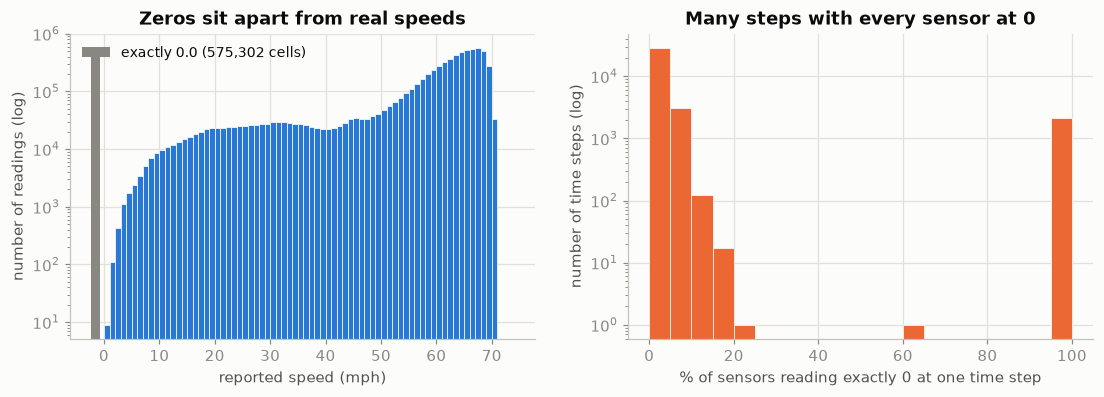

In [6]:
n_nan, n_inf, n_neg = int(np.isnan(values).sum()), int(np.isinf(values).sum()), int((values < 0).sum())
n_zero = int((values == 0).sum())
positive = values[values > 0]
print(f"NaN: {n_nan}   inf: {n_inf}   negative: {n_neg}")
print(f"exactly 0.0: {n_zero:,} cells = {n_zero / values.size:.2%} of all readings")
print(f"smallest positive reading: {positive.min():.2f} mph; readings in (0, 3) mph: {int(((values > 0) & (values < 3)).sum())}")
print(f"largest reading: {values.max():.1f} mph")

zero_share_per_step = (values == 0).mean(axis=1)
all_missing_steps = int((zero_share_per_step == 1.0).sum())
print(f"time steps where ALL {N} sensors are exactly 0: {all_missing_steps:,} ({all_missing_steps / T:.2%} of steps)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(positive, bins=np.arange(0, 75, 1), color="#2a78d6", edgecolor=viz.SURFACE, linewidth=0.5)
axes[0].bar([-1.5], [n_zero], width=1.6, color=viz.MISSING_COLOR, label=f"exactly 0.0 ({n_zero:,} cells)")
axes[0].set_yscale("log"); axes[0].set_xlabel("reported speed (mph)"); axes[0].set_ylabel("number of readings (log)")
axes[0].set_title("Zeros sit apart from real speeds"); axes[0].legend(loc="upper left")
axes[1].hist(zero_share_per_step * 100, bins=np.arange(0, 105, 5), color="#eb6834", edgecolor=viz.SURFACE, linewidth=0.5)
axes[1].set_yscale("log"); axes[1].set_xlabel("% of sensors reading exactly 0 at one time step"); axes[1].set_ylabel("number of time steps (log)")
axes[1].set_title("Many steps with every sensor at 0")
viz.save_figure(fig, "01_zero_encoding"); plt.show()

assert n_nan == 0 and n_inf == 0 and n_neg == 0
assert all_missing_steps > 0, "hypothesis check: expected network-wide all-zero time steps"

**Decision.** Zero is not a speed here: there are time steps at which all 207 sensors read exactly 0.0
simultaneously, which cannot be real congestion. We therefore treat `0.0` as **missing**, convert it to `NaN`,
and keep a boolean *observed* mask. Missing values are never used as a zero speed, in inputs, targets, scalers or
metrics. (DCRNN's reference code also masks `0` as the null value, so the convention matches the literature.)
The smallest *positive* reading is 0.33 mph; very low but non-zero speeds are kept as genuine stop-and-go traffic.

In [7]:
speed, observed = dl.to_speed_and_mask(values)
assert observed.sum() + (~observed).sum() == values.size
assert np.nanmin(speed) > 0, "no observed reading may be zero"
print(f"observed cells: {int(observed.sum()):,}   missing cells: {int((~observed).sum()):,}")

observed cells: 6,519,002   missing cells: 575,302


## 4 · Missingness and potential sensor outages

In [8]:
miss = ~observed
per_sensor = pd.Series(miss.mean(axis=0) * 100, index=sensor_ids, name="missing_%")

def run_lengths(flag: np.ndarray) -> np.ndarray:
    """Lengths of consecutive True runs in a boolean vector."""
    padded = np.r_[False, flag, False].astype(np.int8)
    edges = np.flatnonzero(np.diff(padded))
    return edges[1::2] - edges[0::2]

runs = {sid: run_lengths(miss[:, j]) for j, sid in enumerate(sensor_ids)}
longest = pd.Series({sid: (r.max() if len(r) else 0) for sid, r in runs.items()}, name="longest_missing_run_steps")
all_runs = np.concatenate([r for r in runs.values() if len(r)])

summary = pd.DataFrame({
    "overall missing %": [100 * miss.mean()],
    "per-sensor missing % (min)": [per_sensor.min()],
    "per-sensor missing % (median)": [per_sensor.median()],
    "per-sensor missing % (max)": [per_sensor.max()],
    "sensors > 50% missing": [int((per_sensor > 50).sum())],
    "all-sensor outage steps": [all_missing_steps],
}).T.rename(columns={0: "value"})
display(summary.round(3))

buckets = pd.cut(all_runs, [0, 1, 11, 287, np.inf], labels=["5 min", "10-55 min", "1 h - <1 day", ">= 1 day"])
run_table = pd.DataFrame({
    "gaps": pd.Series(buckets).value_counts().sort_index(),
    "missing cells": pd.Series(all_runs).groupby(buckets, observed=False).sum(),
})
run_table["% of all missing cells"] = 100 * run_table["missing cells"] / miss.sum()
print("Missing gaps by duration (a gap is a maximal run of consecutive missing readings at one sensor):")
display(run_table.round(2))
print("Sensors with the longest single gap (steps of 5 min):")
display(longest.sort_values(ascending=False).head(5).to_frame().assign(days=lambda d: (d.iloc[:, 0] / 288).round(1)))

,value
overall missing %,8.109
per-sensor missing % (min),6.268
per-sensor missing % (median),6.974
per-sensor missing % (max),20.104
sensors > 50% missing,0.000
all-sensor outage steps,2148.000


Missing gaps by duration (a gap is a maximal run of consecutive missing readings at one sensor):


,gaps,missing cells,% of all missing cells
5 min,7468,7468,1.30
10-55 min,11553,46319,8.05
1 h - <1 day,6661,391941,68.13
>= 1 day,281,129574,22.52


Sensors with the longest single gap (steps of 5 min):


,longest_missing_run_steps,days
717491,1683,5.8
717490,1683,5.8
769444,1330,4.6
769430,1330,4.6
769431,1330,4.6


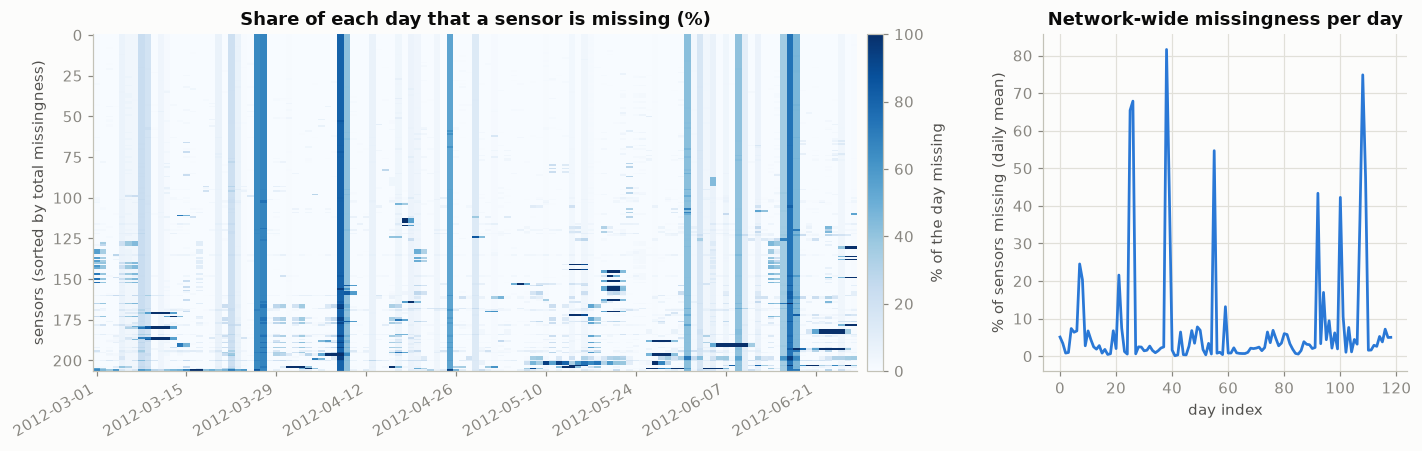

In [9]:
daily_missing = miss.reshape(int(n_days), 288, N).mean(axis=1)            # [days, sensors]
order = np.argsort(per_sensor.values)                                     # least -> most missing
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1.2]})
im = axes[0].imshow(daily_missing[:, order].T * 100, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
axes[0].grid(False)
tick_days = np.arange(0, int(n_days), 14)
axes[0].set_xticks(tick_days, [str(timestamps[d * 288].date()) for d in tick_days], rotation=30, ha="right")
axes[0].set_ylabel("sensors (sorted by total missingness)"); axes[0].set_title("Share of each day that a sensor is missing (%)")
plt.colorbar(im, ax=axes[0], pad=0.01, label="% of the day missing")
axes[1].plot(miss.mean(axis=1).reshape(int(n_days), 288).mean(axis=1) * 100, color="#2a78d6")
axes[1].set_xlabel("day index"); axes[1].set_ylabel("% of sensors missing (daily mean)")
axes[1].set_title("Network-wide missingness per day")
fig.tight_layout(); viz.save_figure(fig, "01_missingness"); plt.show()

**Interpretation.** Missingness is modest for a typical sensor (about 7% of readings) but unevenly distributed in time:
the heatmap shows vertical bands (days on which a large share of all sensors is missing at once, also visible as spikes
in the right panel) and horizontal bands (individual sensors down for several consecutive days; the longest single gap
is listed above). Gaps lasting an hour or longer account for most of the missing cells, so imputing them would mean inventing
long stretches of data.
We therefore keep an observed-mask everywhere, exclude missing *targets* from every loss and metric, and never fill
inputs with future information.

## 5 · Descriptive statistics (observed readings only)

,all observed readings (mph)
count,6519002.00
mean,58.46
std,13.02
min,0.33
1%,13.12
5%,25.62
50%,63.22
95%,68.89
99%,69.75
max,70.00


Distribution across the 207 sensors of each per-sensor statistic:


,mean,std,median,cv
min,30.89,1.99,31.44,0.03
25%,55.38,6.53,60.06,0.11
50%,59.72,10.23,63.00,0.18
75%,62.85,13.43,66.22,0.24
max,67.73,23.94,69.12,0.58


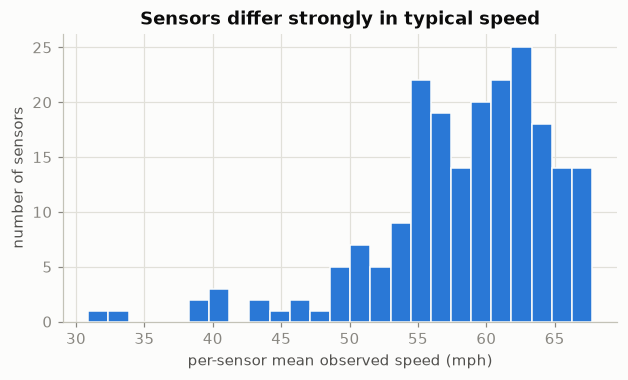

In [10]:
obs_frame = pd.DataFrame(speed, index=timestamps, columns=sensor_ids)
overall = pd.Series(speed[observed]).describe(percentiles=[.01, .05, .5, .95, .99]).rename("all observed readings (mph)")
display(overall.round(2).to_frame())
sensor_stats = obs_frame.agg(["mean", "std", "min", "median", "max", "count"]).T
sensor_stats["cv"] = sensor_stats["std"] / sensor_stats["mean"]
print("Distribution across the 207 sensors of each per-sensor statistic:")
display(sensor_stats.describe().loc[["min", "25%", "50%", "75%", "max"], ["mean", "std", "median", "cv"]].round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(sensor_stats["mean"], bins=25, color="#2a78d6", edgecolor=viz.SURFACE)
ax.set_xlabel("per-sensor mean observed speed (mph)"); ax.set_ylabel("number of sensors"); ax.set_title("Sensors differ strongly in typical speed")
viz.save_figure(fig, "01_sensor_mean_hist"); plt.show()

**Interpretation.** Speeds are capped at 70 mph and the distribution is strongly left-skewed: most readings are in free flow,
a minority are congested. Sensors differ substantially in their typical speed and variability, which is why the models
receive sensor identity (XGBoost), a learned sensor embedding (ST-GAT) and per-sensor training means.

## 6 · Representative sensors

Rather than plotting 207 series, we pick four sensors by an explicit rule: the slowest, the median and the fastest sensor by
mean observed speed, plus the sensor with the highest standard deviation. `plot_sensor` lets you inspect any other id.

                       rule sensor_id
      slowest (lowest mean)    771667
        median-speed sensor    769847
     fastest (highest mean)    767455
most variable (highest std)    717462


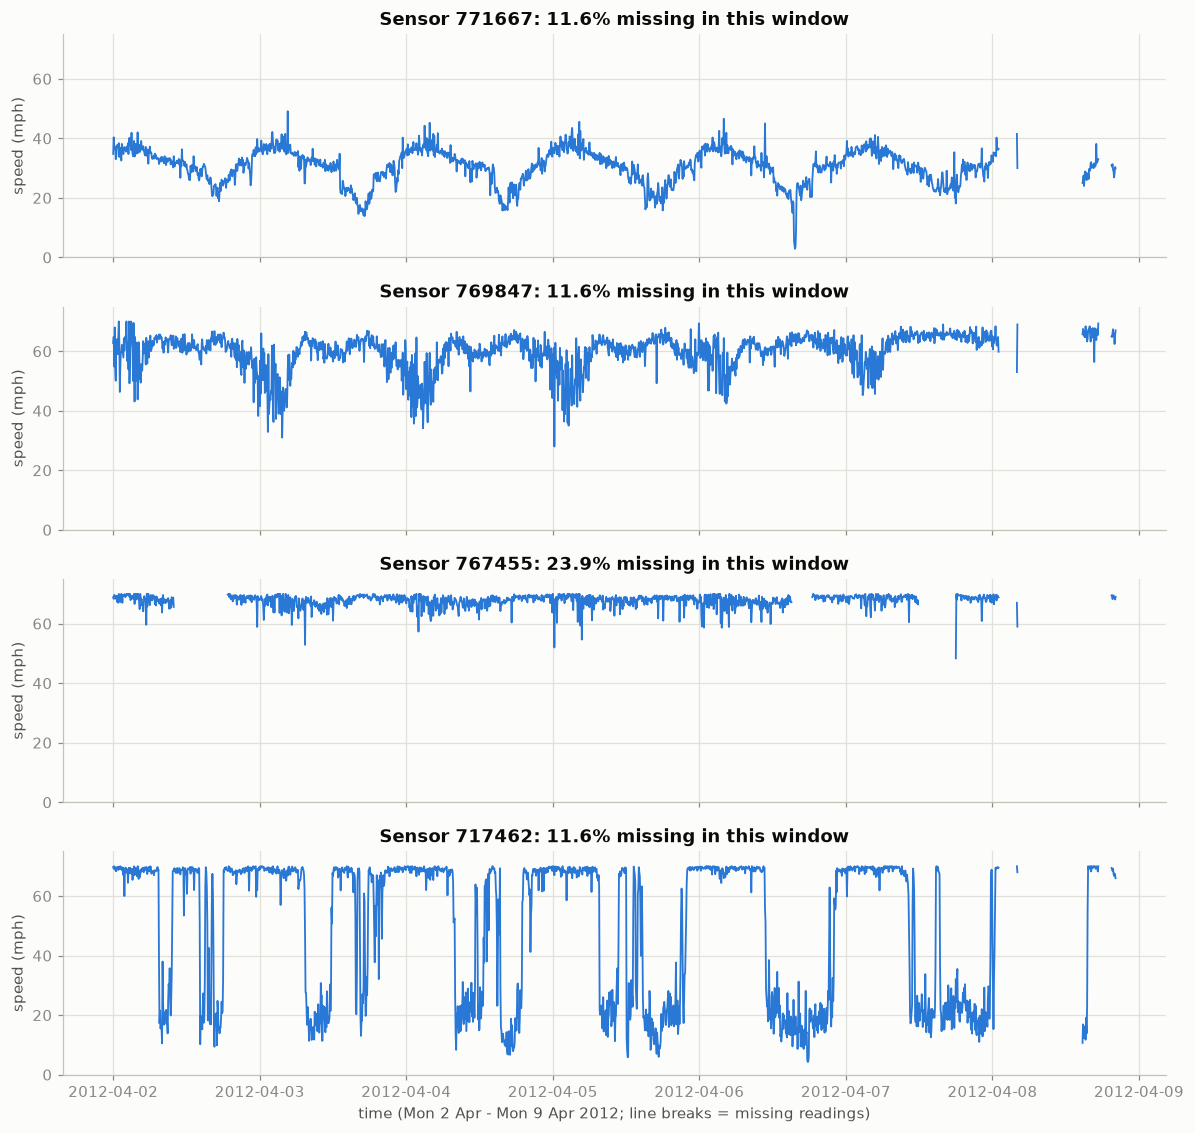

In [11]:
by_mean = sensor_stats["mean"].sort_values()
chosen = {
    "slowest (lowest mean)": by_mean.index[0],
    "median-speed sensor": by_mean.index[len(by_mean) // 2],
    "fastest (highest mean)": by_mean.index[-1],
    "most variable (highest std)": sensor_stats["std"].idxmax(),
}
REP_SENSORS = list(dict.fromkeys(chosen.values()))
print(pd.DataFrame({"rule": list(chosen), "sensor_id": list(chosen.values())}).to_string(index=False))

def plot_sensor(sensor_id, start="2012-04-02", days=7, ax=None):
    """Observed speed of one sensor over `days` days; gaps are real missing readings (line breaks)."""
    ax = ax or plt.subplots(figsize=(11, 2.8))[1]
    window = obs_frame.loc[start:pd.Timestamp(start) + pd.Timedelta(days=days), sensor_id]
    ax.plot(window.index, window.values, color="#2a78d6", lw=1.2)
    ax.set_ylim(0, 75); ax.set_ylabel("speed (mph)")
    ax.set_title(f"Sensor {sensor_id}: {window.isna().mean():.1%} missing in this window")
    return ax

fig, axes = plt.subplots(len(REP_SENSORS), 1, figsize=(11, 2.6 * len(REP_SENSORS)), sharex=True)
for ax, sid in zip(np.atleast_1d(axes), REP_SENSORS):
    plot_sensor(sid, ax=ax)
np.atleast_1d(axes)[-1].set_xlabel("time (Mon 2 Apr - Mon 9 Apr 2012; line breaks = missing readings)")
fig.tight_layout(); viz.save_figure(fig, "01_representative_sensors_week"); plt.show()

**Interpretation.** The plots show a repeating daily rhythm (high free-flow speed at night, dips during commute
periods) with sensor-specific depth and noise. Gaps appear as line breaks, i.e. they stay visible rather than becoming zeros.

## 7 · Network-wide average speed over time

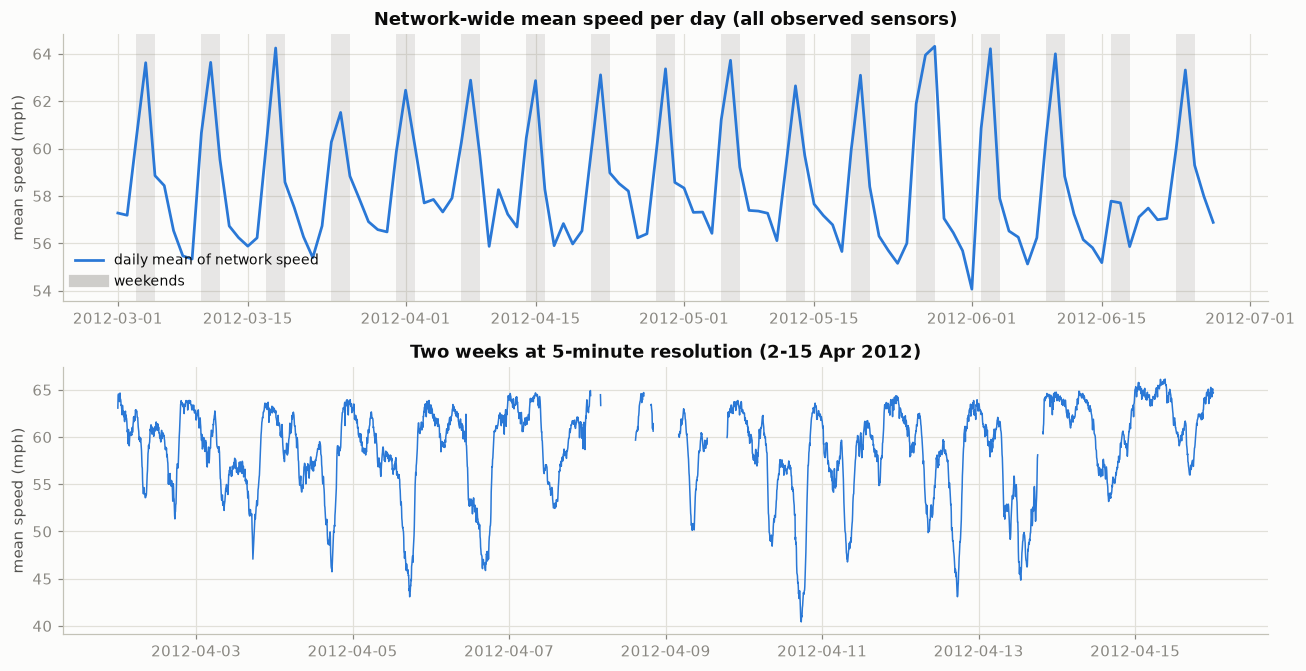

days with the lowest / highest network mean speed:
lowest network mean speed:


,mean mph,weekday
2012-06-01,54.06,Friday
2012-06-07,55.13,Thursday
2012-05-24,55.15,Thursday


highest network mean speed:


,mean mph,weekday
2012-05-28,64.31,Monday
2012-03-18,64.24,Sunday
2012-06-03,64.21,Sunday


mean of daily network speed: weekdays 57.2 mph vs weekends 61.6 mph


In [12]:
n_obs_step = observed.sum(axis=1)
network_mean = pd.Series(np.where(observed, speed, 0.0).sum(axis=1) / np.maximum(n_obs_step, 1), index=timestamps)
network_mean[n_obs_step == 0] = np.nan         # all-sensor outage steps stay undefined, not zero
daily = network_mean.resample("D").mean()
is_weekend = daily.index.dayofweek >= 5

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2))
axes[0].plot(daily.index, daily.values, color="#2a78d6", label="daily mean of network speed")
for d in daily.index[is_weekend]:
    axes[0].axvspan(d, d + pd.Timedelta(days=1), color="#898781", alpha=0.18, lw=0)
axes[0].plot([], [], color="#898781", alpha=0.4, lw=8, label="weekends")
axes[0].set_ylabel("mean speed (mph)"); axes[0].set_title("Network-wide mean speed per day (all observed sensors)"); axes[0].legend(loc="lower left")
two_weeks = network_mean["2012-04-02":"2012-04-15"]
axes[1].plot(two_weeks.index, two_weeks.values, color="#2a78d6", lw=1.0)
axes[1].set_ylabel("mean speed (mph)"); axes[1].set_title("Two weeks at 5-minute resolution (2-15 Apr 2012)")
fig.tight_layout(); viz.save_figure(fig, "01_network_mean_speed"); plt.show()

print("days with the lowest / highest network mean speed:")
for label, days_ in (("lowest", daily.nsmallest(3)), ("highest", daily.nlargest(3))):
    print(f"{label} network mean speed:")
    display(days_.round(2).to_frame("mean mph").assign(weekday=days_.index.day_name()))
weekday_daily, weekend_daily = daily[~is_weekend].mean(), daily[is_weekend].mean()
print(f"mean of daily network speed: weekdays {weekday_daily:.1f} mph vs weekends {weekend_daily:.1f} mph")
assert weekday_daily < weekend_daily

**Interpretation.** The mean of the daily network speed is lower on weekdays than on weekends (asserted above). The days with
the most extreme network means are listed; the data contain no incident, weather or holiday labels, so we do not attribute them
to causes. (Outside the data: 2012-05-28 was the US Memorial Day holiday and falls in the validation period.)

## 8 · Time-of-day and day-of-week structure

Peak periods must be defined *before* models are evaluated. Here we measure the weekday profile and check that the windows
fixed in `config.PEAK_WINDOWS` correspond to the lowest-speed hours. The same profile also supports the assumption that the
naive timestamps are Los Angeles local time (commute dips at around 08:00 and 17:00).

weekday mean speed inside the configured peak windows ((7, 10), (15, 19)): 50.4 mph
weekday mean speed outside them: 60.0 mph   | weekend mean: 61.7 mph
six slowest weekday hours: [8, 9, 15, 16, 17, 18]  -> all inside the peak windows? True


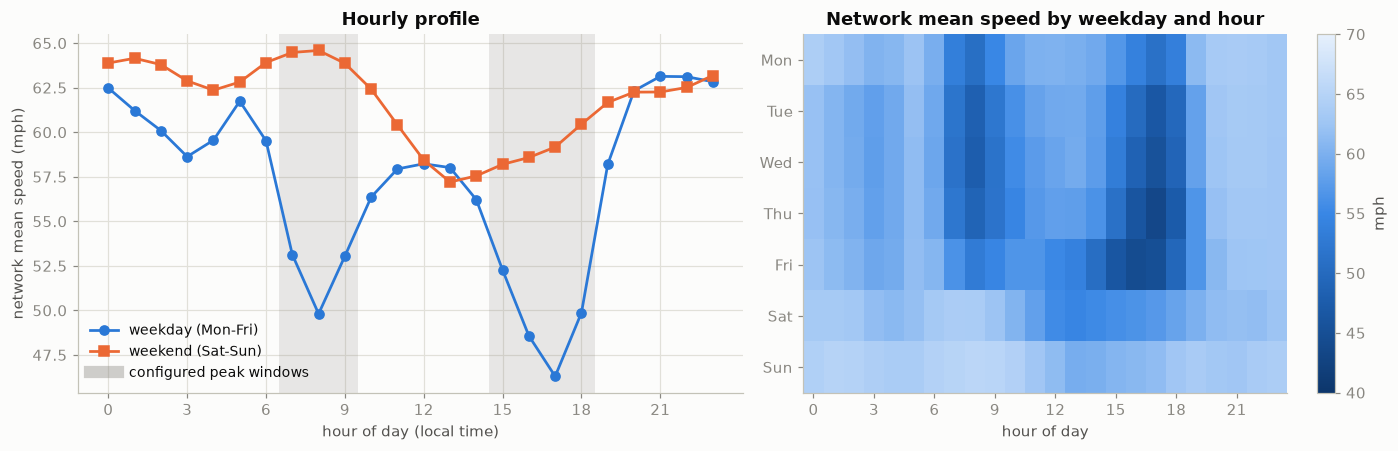

In [13]:
hour = timestamps.hour.to_numpy(); dow = timestamps.dayofweek.to_numpy()
net = network_mean.to_numpy()
weekday = dow < 5

profile = pd.DataFrame({
    "weekday": pd.Series(net[weekday]).groupby(hour[weekday]).mean(),
    "weekend": pd.Series(net[~weekday]).groupby(hour[~weekday]).mean(),
})
dow_hour = pd.DataFrame({"v": net, "dow": dow, "hour": hour}).groupby(["dow", "hour"])["v"].mean().unstack()

in_peak = np.zeros(len(hour), dtype=bool)
for start, end in config.PEAK_WINDOWS:
    in_peak |= (hour >= start) & (hour < end)
peak_mean = np.nanmean(net[weekday & in_peak]); off_mean = np.nanmean(net[weekday & ~in_peak])
weekend_mean = np.nanmean(net[~weekday])
lowest_hours = profile["weekday"].nsmallest(6).index.tolist()
print(f"weekday mean speed inside the configured peak windows {config.PEAK_WINDOWS}: {peak_mean:.1f} mph")
print(f"weekday mean speed outside them: {off_mean:.1f} mph   | weekend mean: {weekend_mean:.1f} mph")
print(f"six slowest weekday hours: {sorted(lowest_hours)}  -> all inside the peak windows? "
      f"{all(any(s <= h < e for s, e in config.PEAK_WINDOWS) for h in lowest_hours)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].plot(profile.index, profile["weekday"], color="#2a78d6", marker="o", label="weekday (Mon-Fri)")
axes[0].plot(profile.index, profile["weekend"], color="#eb6834", marker="s", label="weekend (Sat-Sun)")
for start, end in config.PEAK_WINDOWS:
    axes[0].axvspan(start - 0.5, end - 0.5, color="#898781", alpha=0.18, lw=0)
axes[0].plot([], [], color="#898781", alpha=0.4, lw=8, label="configured peak windows")
axes[0].set_xlabel("hour of day (local time)"); axes[0].set_ylabel("network mean speed (mph)")
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_title("Hourly profile"); axes[0].legend(loc="lower left")
im = axes[1].imshow(dow_hour.values, aspect="auto", cmap=viz.SPEED_CMAP, vmin=40, vmax=70)
axes[1].grid(False); axes[1].set_xticks(range(0, 24, 3)); axes[1].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_xlabel("hour of day"); axes[1].set_title("Network mean speed by weekday and hour")
plt.colorbar(im, ax=axes[1], label="mph")
fig.tight_layout(); viz.save_figure(fig, "01_time_of_day_patterns"); plt.show()

assert peak_mean < off_mean < weekend_mean, "the data do not support the configured peak definition"

**Interpretation (asserted in code above).** On weekdays the network is slower inside the configured peak windows than
outside them, and weekends are faster than weekday off-peak on average. The weekday profile has two pronounced dips
(morning and late afternoon) that line up with local commute hours, which also supports reading the timestamps as Pacific
local time. A smaller dip around 03:00 is visible on weekdays; this data set cannot explain it, so we make no claim about its cause.
The peak definition stays as configured: weekdays 07:00-10:00 and 15:00-19:00 (judged on the forecast *target* time).

## 9 · Representative sensors compared: weekday time-of-day profiles

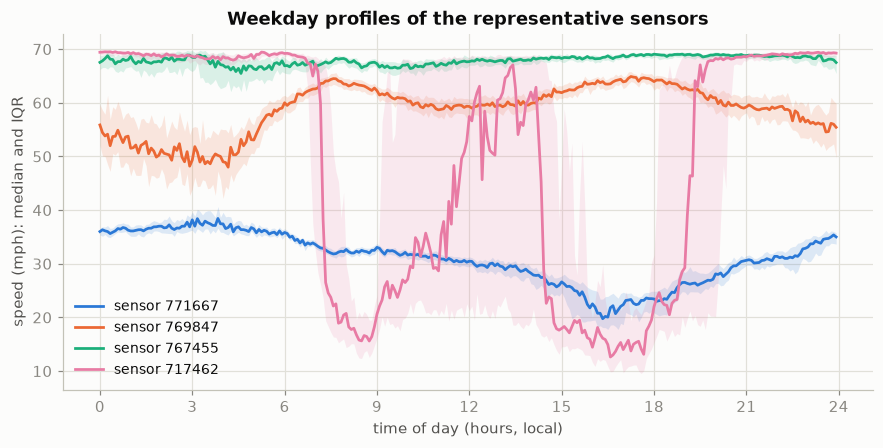

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"]
for color, sid in zip(colors, REP_SENSORS):
    s = obs_frame.loc[weekday, sid]
    tod = (s.index.hour * 60 + s.index.minute) / 60
    prof = s.groupby(tod).agg(["median", lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
    prof.columns = ["median", "q25", "q75"]
    ax.plot(prof.index, prof["median"], color=color, label=f"sensor {sid}")
    ax.fill_between(prof.index, prof["q25"], prof["q75"], color=color, alpha=0.15, lw=0)
ax.set_xlabel("time of day (hours, local)"); ax.set_ylabel("speed (mph): median and IQR"); ax.set_xticks(range(0, 25, 3))
ax.set_title("Weekday profiles of the representative sensors"); ax.legend(loc="lower left")
viz.save_figure(fig, "01_representative_profiles"); plt.show()

**Interpretation.** The same commute structure appears at different depths and with different spreads for each sensor, so a
single network-wide pattern does not describe individual sensors well. Whether nearby sensors share congestion with a time lag
is not shown here; it is exactly what the later models test.

## 10 · Limitations of the dataset

* **Speed only.** METR-LA contains speed. It has no vehicle counts (flow), occupancy, incidents, weather, or holiday labels,
  so we do not model flow and make no claim about it.
* **In-band missing data.** Missing readings are encoded as `0.0`; 8% of cells (and some whole-network time steps) are missing.
  The decision to treat them as missing rests on the evidence in section 3.
* **Short, old, single-region record.** 119 days in 2012, one metropolitan area, highway loop detectors only. The train / validation /
  test periods are contiguous and cover different weeks, so seasonal effects, holidays and infrastructure changes are not controlled.
* **Sensor subset.** 207 of the roughly 4,000 sensors in the district; the graph describes only relationships among those 207.
* **Capped, aggregated measurements.** Speeds are capped at 70 mph and averaged over 5 minutes, hiding within-interval dynamics.
* **Naive timestamps.** No explicit time zone; Pacific local time is an assumption (consistent with the commute pattern above).
* **Observational data.** Low speed at a sensor does not identify an incident or its cause.

In [15]:
checks = {
    "regular 5-minute grid": list(steps.index) == [pd.Timedelta(minutes=5)],
    "207 sensors x 34,272 steps": (T, N) == (34272, 207),
    "zero used as missing sentinel (evidence: all-sensor zero steps)": all_missing_steps > 0,
    "no observed reading equals zero": bool(np.nanmin(speed) > 0),
    "peak windows supported by data": bool(peak_mean < off_mean < weekend_mean),
}
display(pd.DataFrame({"check": list(checks), "result": ["PASS" if v else "FAIL" for v in checks.values()]}))
assert all(checks.values())
print("Exploration complete. Next: 02_data_preprocessing.ipynb")

,check,result
0,regular 5-minute grid,PASS
1,"207 sensors x 34,272 steps",PASS
2,zero used as missing sentinel (evidence: all-s...,PASS
3,no observed reading equals zero,PASS
4,peak windows supported by data,PASS


Exploration complete. Next: 02_data_preprocessing.ipynb
